# Bloc 3 — Notebook 2 : Deep Learning
## Réseau de neurones (MLP) pour le prix et le segment des montres de luxe

**Auteurs du mini-projet :** Ronny Douglas, Victorien Alleg — MSc 2025-2026, Eugenia School  
**Cours :** Machine Learning & Deep Learning (Georgina)

**Question.** Un réseau de neurones fait-il mieux que le Random Forest du notebook 1 sur ce jeu de données tabulaire ?

On construit avec **PyTorch** un perceptron multicouche (MLP) :
- **tête régression** : prédit le log du prix ;
- **tête classification** : prédit Accessible / Premium.

Mêmes données, même découpage 80/20 (graine 42) que le notebook 1 pour une comparaison honnête.

## 1. Données (identiques au notebook 1)

In [1]:
import re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)

df = pd.read_csv("data/luxury_watch.csv", encoding="utf-8-sig")
df["Price (USD)"] = pd.to_numeric(df["Price (USD)"].astype(str).str.replace(",", ""), errors="coerce")
df = df.dropna(subset=["Price (USD)"]).reset_index(drop=True)
df["Complications"] = df["Complications"].fillna("None")
df["Power Reserve"] = df["Power Reserve"].fillna("Unknown")
NUM = ["Case Diameter (mm)", "Case Thickness (mm)", "Band Width (mm)"]
CAT = ["Brand", "Model", "Case Material", "Strap Material", "Movement Type", "Water Resistance",
       "Dial Color", "Crystal Material", "Complications", "Power Reserve"]
TARGET = "Price (USD)"
SEUIL = 8400  # médiane arrondie : frontière Accessible / Premium
df["Premium"] = (df[TARGET] >= SEUIL).astype(int)
print(df.shape)

(506, 15)


In [2]:
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
torch.manual_seed(SEED)
X = pd.get_dummies(df[NUM + CAT], columns=CAT).astype(float)
y_reg, y_clf = df[TARGET], df["Premium"]
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = train_test_split(X, y_reg, y_clf, test_size=0.2, random_state=SEED, stratify=y_clf)
# 15 % du train sert de validation pour l'arrêt anticipé (early stopping)
X_tr2, X_va, yr_tr2, yr_va, yc_tr2, yc_va = train_test_split(X_tr, yr_tr, yc_tr, test_size=0.15, random_state=SEED, stratify=yc_tr)
sc = StandardScaler().fit(X_tr2[NUM])
def prep(Xd):
    Xd = Xd.copy(); Xd[NUM] = sc.transform(Xd[NUM]); return torch.tensor(Xd.values, dtype=torch.float32)
Xt, Xv, Xs = prep(X_tr2), prep(X_va), prep(X_te)
print("Entrées :", Xt.shape[1], "variables | train", len(Xt), "| val", len(Xv), "| test", len(Xs))

Entrées : 250 variables | train 343 | val 61 | test 102


## 2. Architecture
MLP à 2 couches cachées (128 → 64), activation ReLU, *dropout* 0,2 contre le sur-apprentissage, optimiseur Adam avec *weight decay* (régularisation L2). La régression apprend le **log du prix** pour atténuer la longue traîne.

In [3]:
class MLP(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, 128), nn.ReLU(), nn.Dropout(0.2),
                                 nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, d_out))
    def forward(self, x): return self.net(x)

def entrainer(model, loss_fn, Xtr, ytr, Xva, yva, epochs=600, lr=1e-3, patience=40):
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    hist, best, best_state, wait = {"train": [], "val": []}, 1e9, None, 0
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 32):
            idx = perm[i:i + 32]; opt.zero_grad(); l = loss_fn(model(Xtr[idx]), ytr[idx]); l.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            lt, lv = loss_fn(model(Xtr), ytr).item(), loss_fn(model(Xva), yva).item()
        hist["train"].append(lt); hist["val"].append(lv)
        if lv < best - 1e-5: best, best_state, wait = lv, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state); return hist
print(MLP(Xt.shape[1], 1))

MLP(
  (net): Sequential(
    (0): Linear(in_features=250, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


## 3. Régression du prix

Époques : 53 | {'R²': 0.867, 'RMSE': 3715.114, 'MAE': 2078.393}


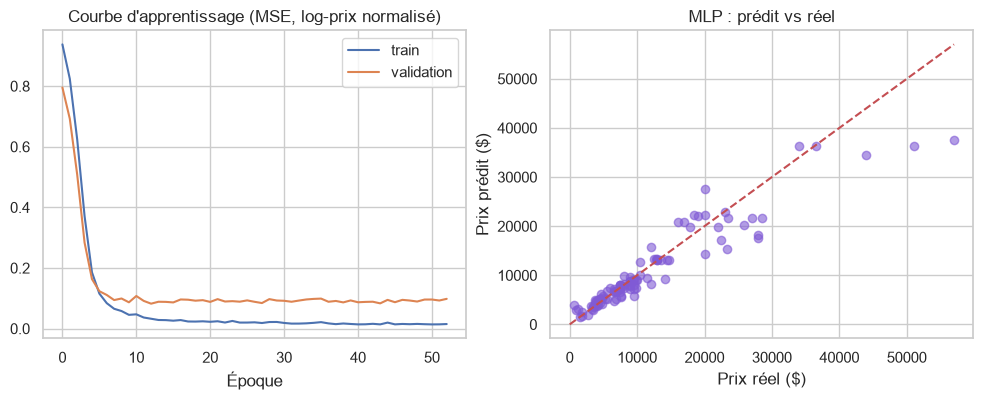

In [4]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
mu, sd = np.log(yr_tr2).mean(), np.log(yr_tr2).std()
ylog = lambda s: torch.tensor(((np.log(s.values) - mu) / sd)[:, None], dtype=torch.float32)
reg = MLP(Xt.shape[1], 1)
h_reg = entrainer(reg, nn.MSELoss(), Xt, ylog(yr_tr2), Xv, ylog(yr_va))
with torch.no_grad(): p_mlp = np.exp(reg(Xs).numpy().ravel() * sd + mu)
r_mlp = {"R²": r2_score(yr_te, p_mlp), "RMSE": mean_squared_error(yr_te, p_mlp) ** .5, "MAE": mean_absolute_error(yr_te, p_mlp)}
print("Époques :", len(h_reg["train"]), "|", {k: round(v, 3) for k, v in r_mlp.items()})
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(h_reg["train"], label="train"); axs[0].plot(h_reg["val"], label="validation"); axs[0].set_title("Courbe d'apprentissage (MSE, log-prix normalisé)"); axs[0].set_xlabel("Époque"); axs[0].legend()
m = yr_te.max(); axs[1].scatter(yr_te, p_mlp, alpha=.6, color="#805ad5"); axs[1].plot([0, m], [0, m], "r--"); axs[1].set_xlabel("Prix réel ($)"); axs[1].set_ylabel("Prix prédit ($)"); axs[1].set_title("MLP : prédit vs réel")
plt.savefig("figs/13_mlp_regression.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Classification Accessible / Premium

Époques : 48 | Accuracy : 0.912 | ROC-AUC : 0.976
              precision    recall  f1-score   support

  Accessible       0.89      0.94      0.91        51
     Premium       0.94      0.88      0.91        51

    accuracy                           0.91       102
   macro avg       0.91      0.91      0.91       102
weighted avg       0.91      0.91      0.91       102



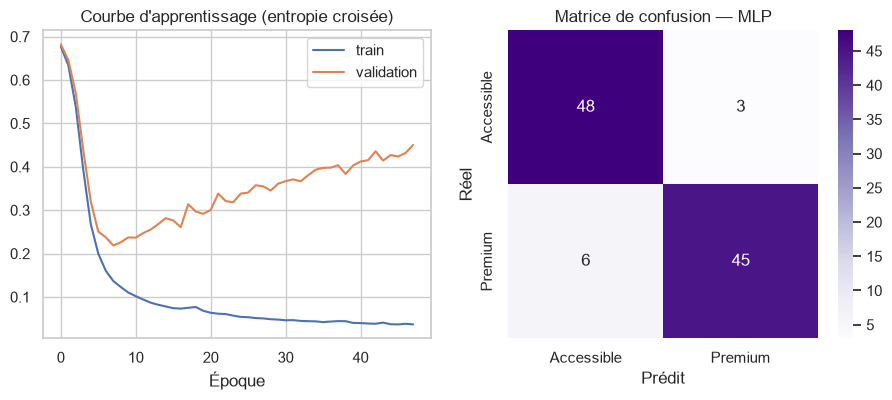

In [5]:
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
yt = lambda s: torch.tensor(s.values[:, None], dtype=torch.float32)
clf = MLP(Xt.shape[1], 1)
h_clf = entrainer(clf, nn.BCEWithLogitsLoss(), Xt, yt(yc_tr2), Xv, yt(yc_va))
with torch.no_grad(): pr = torch.sigmoid(clf(Xs)).numpy().ravel()
pc = (pr >= .5).astype(int)
print(f"Époques : {len(h_clf['train'])} | Accuracy : {accuracy_score(yc_te, pc):.3f} | ROC-AUC : {roc_auc_score(yc_te, pr):.3f}")
print(classification_report(yc_te, pc, target_names=["Accessible", "Premium"]))
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(h_clf["train"], label="train"); axs[0].plot(h_clf["val"], label="validation"); axs[0].set_title("Courbe d'apprentissage (entropie croisée)"); axs[0].set_xlabel("Époque"); axs[0].legend()
sns.heatmap(confusion_matrix(yc_te, pc), annot=True, fmt="d", cmap="Purples", ax=axs[1], xticklabels=["Accessible", "Premium"], yticklabels=["Accessible", "Premium"])
axs[1].set_xlabel("Prédit"); axs[1].set_ylabel("Réel"); axs[1].set_title("Matrice de confusion — MLP")
plt.savefig("figs/14_mlp_classification.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Comparaison avec le Machine Learning classique

In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
rf = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X_tr, yr_tr); p_rf = rf.predict(X_te)
lg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_tr, yc_tr)
tab = pd.DataFrame({
    "Random Forest (ML)": {"R² prix": r2_score(yr_te, p_rf), "RMSE prix ($)": mean_squared_error(yr_te, p_rf) ** .5},
    "MLP (DL)": {"R² prix": r_mlp["R²"], "RMSE prix ($)": r_mlp["RMSE"]}}).T
tab["Accuracy segment"] = [accuracy_score(yc_te, lg.predict(X_te)), accuracy_score(yc_te, pc)]
tab.index = ["ML : Random Forest / Rég. logistique", "DL : MLP PyTorch"]
display(tab.round(3))

,R² prix,RMSE prix ($),Accuracy segment
ML : Random Forest / Rég. logistique,0.876,3581.555,0.922
DL : MLP PyTorch,0.867,3715.114,0.912


## 6. Conclusions
- Sur **506 lignes tabulaires**, le réseau de neurones **ne surpasse pas nettement** le Random Forest : c'est le résultat attendu. Les modèles à base d'arbres restent la référence sur les petites données tabulaires ; le deep learning brille sur les grands volumes et les données non structurées (images, texte, son).
- Le MLP demande plus de réglages (normalisation, log du prix, dropout, early stopping) pour un gain faible ou nul ici.
- **Recommandation** : en production, garder le **Random Forest** (plus simple, plus explicable via l'importance des variables). Le deep learning deviendrait pertinent avec des **photos de montres** (CNN) ou des **descriptions d'annonces** (modèles de langue) pour enrichir la prédiction.